# 01 — EDA: Model A raw datasets (issue #17)

Look-only notebook: it never changes data. Cleaning runs from `ml/knowledge/scripts/build_dataset.py`.
Paths come from `ml/knowledge/configs/build.yaml` (`dvc pull` first). Run from the repo root.

1. ASSISTments 2009-2010 skill builder (`skill_builder_data_corrected_collapsed.csv`)
2. EdNet KT1 sample (`EdNet-KT1.zip` + `questions.csv`)


## 1. ASSISTments 2009-2010 skill builder

In [ ]:
import io
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

while not Path("pyproject.toml").exists():
    os.chdir("..")
CFG = yaml.safe_load(Path("ml/knowledge/configs/build.yaml").read_text())
df = pd.read_csv(
    CFG["assistments"]["raw_path"],
    encoding=CFG["assistments"]["encoding"],
    dtype={"skill_id": str},
    low_memory=False,
)
print(f"rows {len(df):,}  columns {df.shape[1]}")

rows 346,860  columns 31


## Missing values per column

In [2]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False).to_frame("missing_rows").assign(
    pct=lambda m: (100 * m.missing_rows / len(df)).round(2)
)

,missing_rows,pct
answer_id,306818,88.46
bottom_hint,287003,82.74
answer_text,77630,22.38
skill_name,72270,20.84
opportunity_original,71402,20.59
skill_id,63755,18.38


## Duplicates and cardinality

In [3]:
print(f"duplicate order_id rows: {df.order_id.duplicated().sum():,}")
print(
    f"students {df.user_id.nunique():,}  skills {df.skill_id.nunique():,}  "
    f"problems {df.problem_id.nunique():,}"
)
print(f"original==0 (scaffolding) rows: {(df.original == 0).sum():,}")
print(f"multi-skill rows (skill_id contains '_'): {df.skill_id.str.contains('_', na=False).sum():,}")

duplicate order_id rows: 0


students 4,217  skills 149  problems 26,688
original==0 (scaffolding) rows: 71,402
multi-skill rows (skill_id contains '_'): 47,037


## Answers per student

count    4217.0
mean       82.3
std       163.7
min         1.0
25%        10.0
50%        23.0
75%        74.0
max      1383.0
students with < 10 answers: 1,049


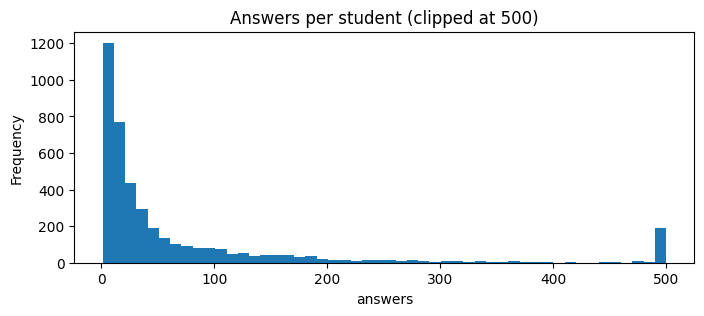

In [4]:
per_student = df.user_id.value_counts()
print(per_student.describe().round(1).to_string())
print(f"students with < 10 answers: {(per_student < 10).sum():,}")
ax = per_student.clip(upper=500).plot.hist(
    bins=50, figsize=(8, 3), title="Answers per student (clipped at 500)"
)
ax.set_xlabel("answers")
plt.show()

## Correct rate

In [5]:
print(f"overall correct rate: {df.correct.mean():.4f}")
print(f"original problems only: {df[df.original == 1].correct.mean():.4f}")
print("values of correct:", sorted(df.correct.unique()))

overall correct rate: 0.6453
original problems only: 0.6584
values of correct: [np.int64(0), np.int64(1)]


## Response time (`ms_first_response`)

<= 0 ms: 317   negative: 7
99th percentile: 336,042 ms   max: 84,076,920 ms


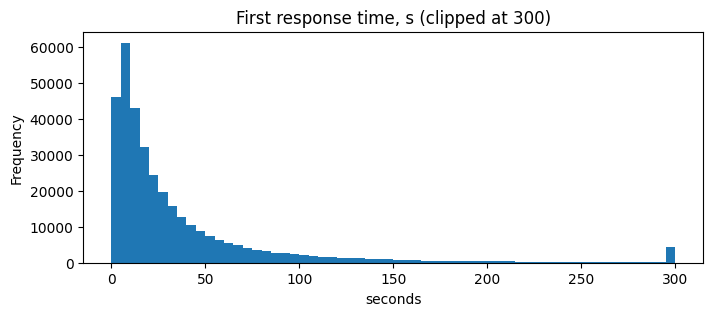

In [6]:
rt = df.ms_first_response
print(f"<= 0 ms: {(rt <= 0).sum():,}   negative: {(rt < 0).sum():,}")
print(f"99th percentile: {rt.quantile(0.99):,.0f} ms   max: {rt.max():,.0f} ms")
ax = (
    (rt[rt > 0] / 1000)
    .clip(upper=300)
    .plot.hist(bins=60, figsize=(8, 3), title="First response time, s (clipped at 300)")
)
ax.set_xlabel("seconds")
plt.show()

## Answers per skill

In [7]:
per_skill = df.skill_id.value_counts()
print(f"skills with < 20 answers: {(per_skill < 20).sum():,}")
per_skill.head(10).to_frame("answers")

skills with < 20 answers: 14


,answers
skill_id,
311,24253
47,18739
277,12741
280,11334
312,8115
79,8068
279,7058
27,6590
18,6557


## 2. EdNet KT1 sample

Seeded sample of 2,000 student files (seed from the config, 42) read straight from `EdNet-KT1.zip`,
joined to `questions.csv` for the answer key. Same reading logic as `load_ednet_sample()` in
`build_dataset.py`. No per-student rows are shown (privacy rule).

In [ ]:
EDA_SAMPLE_STUDENTS = 2000
questions = pd.read_csv(CFG["ednet"]["questions_csv"], usecols=["question_id", "correct_answer", "tags"])
frames = []
with zipfile.ZipFile(CFG["ednet"]["kt1_zip"]) as archive:
    members = sorted(n for n in archive.namelist() if n.endswith(".csv") and Path(n).stem.startswith("u"))
    rng = np.random.default_rng(CFG["seed"])
    sample = rng.choice(members, size=min(EDA_SAMPLE_STUDENTS, len(members)), replace=False)
    for name in sorted(sample):
        user = pd.read_csv(io.BytesIO(archive.read(name)))
        user["user_id"] = Path(name).stem
        frames.append(user)
ednet = pd.concat(frames, ignore_index=True).merge(questions, on="question_id", how="left")
print(f"student files in zip: {len(members):,}   sampled: {len(sample):,}")
print(f"interactions {len(ednet):,}  columns {ednet.shape[1]}")
print(f"questions.csv rows: {len(questions):,}")

## Missing values per column

In [ ]:
missing = ednet.isna().sum()
missing[missing > 0].sort_values(ascending=False).to_frame("missing_rows").assign(
    pct=lambda m: (100 * m.missing_rows / len(ednet)).round(4)
)

## Cardinality and correct rate

Rows with a missing `user_answer` are excluded from the correct rate instead of being counted as wrong.

In [ ]:
has_answer = ednet.user_answer.notna()
answered = ednet[has_answer]
is_correct = answered.user_answer == answered.correct_answer
print(f"students {ednet.user_id.nunique():,}  questions {ednet.question_id.nunique():,}")
print(f"unique tag combinations: {ednet.tags.nunique():,}")
print(f"questions missing from questions.csv: {ednet.correct_answer.isna().sum():,}")
print(f"missing user_answer (excluded): {(~has_answer).sum():,}")
print(f"overall correct rate (answered only): {is_correct.mean():.4f}")

## Answers per student and elapsed time

In [ ]:
per_student_ednet = ednet.user_id.value_counts()
print(per_student_ednet.describe().round(1).to_string())
elapsed = ednet.elapsed_time
print(f"<= 0 ms: {(elapsed <= 0).sum():,}   99th percentile: {elapsed.quantile(0.99):,.0f} ms")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_student_ednet.clip(upper=1000).plot.hist(
    bins=50, ax=axes[0], title="EdNet: answers per student (clipped at 1000)"
)
axes[0].set_xlabel("answers")
(elapsed[elapsed > 0] / 1000).clip(upper=120).plot.hist(
    bins=60, ax=axes[1], title="EdNet: elapsed time, s (clipped at 120)"
)
axes[1].set_xlabel("seconds")
plt.tight_layout()
plt.show()